![Logo Javeriana](https://images.seeklogo.com/logo-png/11/1/pontificia-universidad-javeriana-logo-png_seeklogo-110703.png)

# Nombre: Gabriel Jaramillo Cuberos (Id: 20529022)

Materia: Procesamiento de Datos (1255)

Tema: Taller de Hadoop - Comparación de formatos de datasets

Fecha: 3 de noviembre de 2026

Objetivos: 
- Aplicar la metodología CRISP-DM en datasets de las ciencias de la salud
- Documentar de forma exhaustiva cada actividad realizada de la metodología
- Crear y analizar gráficas: comprender la creación de gráficas como imágenes que documenten de forma académica
- Hacer las recomendaciones, conclusiones, análisis correspondientes
- Hacer uso del entorno IDE Python cuaderno: servidor personal
- Usar un dataset de Accidentes Cerebro Vaculares
- Hacer análisis y conclusiones

Nombre del fichero: Jaramillo_HadoopHDFS.ipynb

In [1]:
#Generic Libraries
import numpy as np                  # linear algebra
import pandas as pd                 # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib as mtplib
import seaborn as sns               # Creación de gráficas y biblioteca estadística
import matplotlib.pyplot as plt     # Implementación de gráfica

import findspark
findspark.init("/mnt/sda1/Cluster/Spark/")

#Apache Spark Libraries
from pyspark import SparkConf, SparkContext                    # SparkConf:       // SparkContext:
from pyspark.sql import SparkSession, SQLContext

from pyspark.sql import functions as F                           # Se importan todas las funciones: when, column, ...
from pyspark.sql.types import *

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipelin Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector

#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split

from datetime import date

#Tabulating Data
#from tabulate import tabulate

#Garbage
import gc

In [2]:
# Se crea una configuración para la sesión SPARK

#Configuración del clúster del profesor John Corredor
configura = SparkConf().set("spark.ui.port","37010") # Configuración del puerto
configura.setAppName("HDFSJaramillo")

sparkJaramillo = SparkSession.builder.config(conf = configura).getOrCreate()
SQLContext(sparkContext = sparkJaramillo.sparkContext, sparkSession = sparkJaramillo)

sparkContextJaramillo = sparkJaramillo.sparkContext.getOrCreate()

print("Sesión creada el", date.today())
sparkJaramillo

#Configuración del clúster del grupo
#sparkJaramillo = (
#    SparkSession.builder
#    .appName("DerrameBigData_Jaramillo")
#    .master("spark://10.43.97.76:8888")
#    .config("spark.pyspark.python", "/usr/bin/python3.11")
#    .config(
#        "spark.scheduler.allocation.file",
#        "file:///opt/cluster/spark/conf/fairscheduler.xml"
#    )
#    .config("spark.executor.memory", "1g")
#    .config("spark.executor.cores", "2")
#    .config("spark.cores.max", "2")
#    .getOrCreate()
#)

#SQLContext(
#    sparkContext = sparkJaramillo.sparkContext,
#    sparkSession = sparkJaramillo
#)

## Se levanta el contexto para la sesión: Aplicación de Derrame Cerebral en SPARK
#sparkContextJaramillo = sparkJaramillo.sparkContext.getOrCreate()

## Se imprime para verificar
#print("Sesión creada el", date.today())
#sparkJaramillo

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesión creada el 2026-11-03


In [7]:
# Creación de carpeta
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir /Formatos1255/JaramilloCuberos

In [8]:
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir /Formatos1255/JaramilloCuberos/datasets

In [9]:
# Subir dataset de clientes
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put customers-2000000.csv /Formatos1255/JaramilloCuberos/datasets

In [10]:
# Comprobar archivo
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1255/JaramilloCuberos/datasets

Found 1 items
-rw-r--r--   2 usuario10 supergroup  349423206 2026-11-03 07:24 /Formatos1255/JaramilloCuberos/datasets/customers-2000000.csv


In [11]:
# Se crean las carpetas Parquet y ORC
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir /Formatos1255/JaramilloCuberos/ORC
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir /Formatos1255/JaramilloCuberos/Parquet

In [12]:
# Se requiere crear el fichero de formato CSV

# Primero se hace el dataframe del CSV

urlCSV = "hdfs://10.195.34.34:9000/Formatos1255/JaramilloCuberos/datasets/customers-2000000.csv"

dfCSV = sparkJaramillo.read.format("csv") \
        .option("header", "true") \
        .option("inferSchema", "true")\
        .load(urlCSV) # Establecer ruta del archivo

dfCSV.head(5)

[Row(Index=1, Customer Id='069ddDc14D23C30', First Name='Morgan', Last Name='Zamora', Company='Kent LLC', City='Lake Sheliatown', Country='Ireland', Phone 1='(142)005-7881x094', Phone 2='924.538.5262x097', Email='warrencombs@chaney-becker.info', Subscription Date=datetime.date(2022, 3, 22), Website='http://english.com/'),
 Row(Index=2, Customer Id='5ceFDfeC1059FB7', First Name='Sharon', Last Name='Schultz', Company='Hess and Sons', City='East Dustinshire', Country='Central African Republic', Phone 1='726-654-5854', Phone 2='001-689-133-4593x34131', Email='middletonwilliam@french-rubio.com', Subscription Date=datetime.date(2020, 5, 26), Website='http://ellison.org/'),
 Row(Index=3, Customer Id='85F9bbe4bEB3B12', First Name='Desiree', Last Name='Rowland', Company='Moran, Rocha and Russell', City='Phillipfort', Country='Mongolia', Phone 1='787.244.6052x30446', Phone 2='(694)031-4832x80724', Email='mariohanson@ramsey-david.biz', Subscription Date=datetime.date(2020, 5, 16), Website='https:

In [13]:
# Se crea el formato Parquet
dfCSV.write.mode("overwrite").parquet("hdfs://10.195.34.34:9000/Formatos1255/JaramilloCuberos/Parquet")

# Se crea el formato ORC
dfCSV.write.mode("overwrite").orc("hdfs://10.195.34.34:9000/Formatos1255/JaramilloCuberos/ORC")

In [15]:
# Comprobar archivos
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1255/JaramilloCuberos/Parquet
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1255/JaramilloCuberos/ORC

Found 6 items
-rw-r--r--   3 usuario10 supergroup          0 2026-11-03 07:27 /Formatos1255/JaramilloCuberos/Parquet/_SUCCESS
-rw-r--r--   3 usuario10 supergroup   42204517 2026-11-03 07:27 /Formatos1255/JaramilloCuberos/Parquet/part-00000-3cd4ea1a-0d7a-43d8-b42e-28832a17fbcd-c000.snappy.parquet
-rw-r--r--   3 usuario10 supergroup   42139428 2026-11-03 07:27 /Formatos1255/JaramilloCuberos/Parquet/part-00001-3cd4ea1a-0d7a-43d8-b42e-28832a17fbcd-c000.snappy.parquet
-rw-r--r--   3 usuario10 supergroup   42008877 2026-11-03 07:27 /Formatos1255/JaramilloCuberos/Parquet/part-00002-3cd4ea1a-0d7a-43d8-b42e-28832a17fbcd-c000.snappy.parquet
-rw-r--r--   3 usuario10 supergroup   41893297 2026-11-03 07:27 /Formatos1255/JaramilloCuberos/Parquet/part-00003-3cd4ea1a-0d7a-43d8-b42e-28832a17fbcd-c000.snappy.parquet
-rw-r--r--   3 usuario10 supergroup   39391541 2026-11-03 07:27 /Formatos1255/JaramilloCuberos/Parquet/part-00004-3cd4ea1a-0d7a-43d8-b42e-28832a17fbcd-c000.snappy.parquet
Found 6 items
-rw-r

In [16]:
# Toma de medidas en la creación de objetos DATAFRAME de tipo PySpark

import time

iniTimeCSV = time.time()
urlCSV = "hdfs://10.195.34.34:9000/Formatos1255/JaramilloCuberos/datasets/customers-2000000.csv"
DFCSV = sparkJaramillo.read.format("csv").option("header","true").load(urlCSV)
finTimeCSV = time.time()

iniTimeORC = time.time()
urlORC = "hdfs://10.195.34.34:9000/Formatos1255/JaramilloCuberos/ORC/*"
DFORC = sparkJaramillo.read.format("orc").option("header","true").load(urlORC)
finTimeORC = time.time()

iniTimeParquet = time.time()
urlParquet = "hdfs://10.195.34.34:9000/Formatos1255/JaramilloCuberos/Parquet/*"
DFParquet = sparkJaramillo.read.format("parquet").option("header","true").load(urlParquet)
finTimeParquet = time.time()

In [17]:
# Se presentan los tiempos

tiempoCSV = finTimeCSV - iniTimeCSV
tiempoORC = finTimeORC - iniTimeORC
tiempoParquet = finTimeParquet - iniTimeParquet

# Comparativa de tiempos
print(f"Tiempo de creacion dataframe formato CSV = {round(tiempoCSV,2)} seg")
print(f"Tiempo de creacion dataframe formato ORC = {round(tiempoORC,2)} seg")
print(f"Tiempo de creacion dataframe formato Parquet = {round(tiempoParquet,2)} seg")

Tiempo de creacion dataframe formato CSV = 5.91 seg
Tiempo de creacion dataframe formato ORC = 0.16 seg
Tiempo de creacion dataframe formato Parquet = 0.27 seg


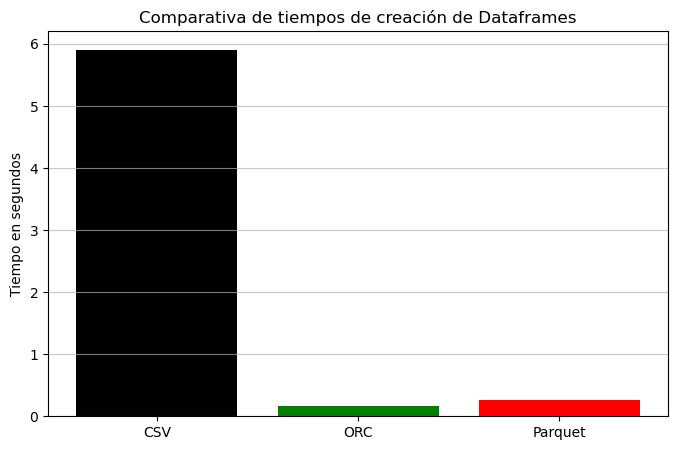

In [22]:
# Creación de gráficas para la comparación

# Establecer variables medibles
formatos = ['CSV', 'ORC', 'Parquet']
tiempos = [tiempoCSV, tiempoORC, tiempoParquet]

plt.figure(figsize=(8, 5))
barras = plt.bar(formatos, tiempos, color=['black', 'green', 'red'])

# Establecer etiquetas y título
plt.ylabel('Tiempo en segundos')
plt.title('Comparativa de tiempos de creación de Dataframes')
plt.grid(axis='y', alpha=0.7)

plt.show()


## **Conclusión:**

- Analizando la gráfica comparativa de tiempos de creación de Dataframes, se puede observar que los archivos en formato CSV tienen un tiempo de creación notablemente mayor que los archivos en ORC o Parquet.
- Si se busca eficiencia para la cración de dataframes, el mejor formato es ORC, ya que tiene el menor tiempo de creación en la comparativa

## *Cierre de sesión:*

In [23]:
# Se detiene la aplicación

sparkJaramillo.stop()